In [1]:
import pandas as pd
import numpy as np

In [43]:
data=pd.read_csv("DateFruit_Dataset.csv")
data.head()

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


In [44]:
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split
x=data.drop(["Class"],axis=1)
y=data["Class"]
le=LabelEncoder()
y_encoded=le.fit_transform(y)
x_train,x_test,y_train,y_test=train_test_split(x,y_encoded,test_size=0.2,random_state=42)
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [45]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset,DataLoader


In [46]:
X_train_tensor = torch.tensor(x_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(x_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [47]:
class Ann(nn.Module):
    def __init__(self):
        super(Ann,self).__init__()
        self.model=nn.Sequential(
            nn.Linear(x.shape[1],32),
            nn.ReLU(),
            nn.Linear(32,16),
            nn.ReLU(),
            nn.Linear(16,7)
        )
    def forward(self,x):
            return self.model(x)
        

In [48]:
model=Ann()
criteria=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters())

In [49]:
epochs=100
train_losses=[]
test_losses=[]
for epoch in range (epochs):
    running_loss=0
    test_loss=0
    model.train()
    for xb,yb in train_loader:
        optimizer.zero_grad()
        output=model(xb)
        loss=criteria(output,yb)
        loss.backward()
        optimizer.step()
        running_loss+=loss.item()
    train_loss=running_loss/len(train_loader)
    train_losses.append(train_loss)
    print(f"epoch={epoch+1}/{epochs},train_loss={train_loss}")
    model.eval()
    with torch.no_grad():
        for xb,yb in test_loader:
            outp=model(xb)
            loss=criteria(outp,yb)
            test_loss+=loss.item()
    test_loss=test_loss/len(test_loader)
    test_losses.append(test_loss)
    print(f"epoch={epoch+1}/{epochs},test_loss={test_loss}")
        

epoch=1/100,train_loss=1.8638006085934846
epoch=1/100,test_loss=1.7392974694569905
epoch=2/100,train_loss=1.599032329476398
epoch=2/100,test_loss=1.4173812071482341
epoch=3/100,train_loss=1.2584339380264282
epoch=3/100,test_loss=1.1215616861979167
epoch=4/100,train_loss=1.0216308521187825
epoch=4/100,test_loss=0.943984587987264
epoch=5/100,train_loss=0.8576052603514298
epoch=5/100,test_loss=0.7893133958180746
epoch=6/100,train_loss=0.7110069355239039
epoch=6/100,test_loss=0.6633183062076569
epoch=7/100,train_loss=0.6057922827160876
epoch=7/100,test_loss=0.5773823956648508
epoch=8/100,train_loss=0.545519910428835
epoch=8/100,test_loss=0.514756957689921
epoch=9/100,train_loss=0.48222362930360047
epoch=9/100,test_loss=0.47313333054383594
epoch=10/100,train_loss=0.45299865370211395
epoch=10/100,test_loss=0.4255577623844147
epoch=11/100,train_loss=0.4156741486943286
epoch=11/100,test_loss=0.3995920146505038
epoch=12/100,train_loss=0.38949657587901404
epoch=12/100,test_loss=0.369599464039007

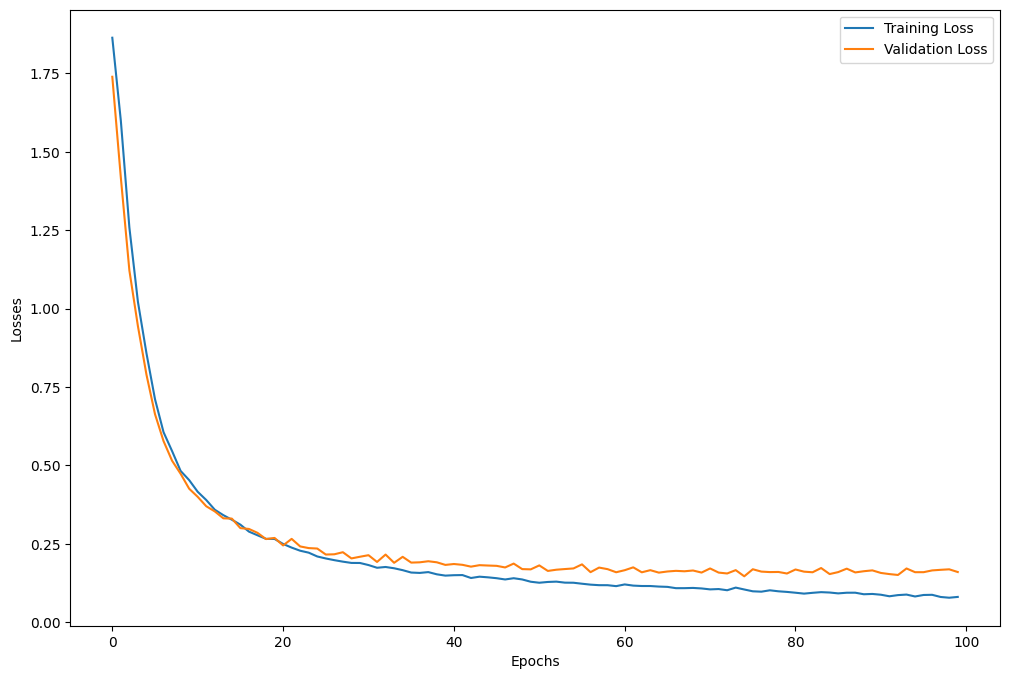

In [50]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,8))
plt.plot(train_losses, label="Training Loss")
plt.plot(test_losses, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

In [ ]:
# Evaluate
model.eval()

total = 0
correct = 0

with torch.no_grad():
    for xb, yb in test_loader:
        outputs = model(xb)              # [0.2, 0.5, 1.3, -0.5, -1, ...] - 7 vals
        _, predicted = torch.max(outputs, 1)

        correct += (predicted == yb).sum().item()
        total += yb.size(0)              # actual samples in each batch

print("total vals:", total)
print("correct vals:", correct)